In [2]:
import numpy as np
import gudhi

from gudhi.wasserstein import wasserstein_distance

In [8]:
from pathlib import Path

def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "processed_data").exists() and (candidate / "labeled_data").exists():
            return candidate
        nested = candidate / "levelset_urban_ph"
        if (nested / "processed_data").exists() and (nested / "labeled_data").exists():
            return nested
    raise FileNotFoundError(f"Could not find levelset_urban_ph from {start.resolve()}")

LEVELSET_ROOT = find_levelset_root()
NOTEBOOK_DIR = LEVELSET_ROOT / "notebooks_clustering"
EXAMPLE_DATA_DIR = LEVELSET_ROOT / "processed_data" / "example_cities"

pd_h1 = np.loadtxt(EXAMPLE_DATA_DIR / "grid_manhattan" / "manhattan_h1.csv", delimiter=",")
pd_h2 = np.loadtxt(EXAMPLE_DATA_DIR / "grid_chicago" / "chicago_h1.csv", delimiter=",")
pd_h3 = np.loadtxt(EXAMPLE_DATA_DIR / "organic_lisbon" / "lisbon_h1.csv", delimiter=",")
pd_h4 = np.loadtxt(NOTEBOOK_DIR / "culdesac.csv", delimiter=",")
pd_h5 = np.loadtxt(NOTEBOOK_DIR / "grid.csv", delimiter=",")

In [15]:
pd_h5

array([[ 0. , 64.6],
       [ 0. , 57.5],
       [ 0. , 46.6],
       [ 0. , 36.4],
       [ 0. , 35.8],
       [ 0. , 34. ],
       [ 0. , 33.2],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 29. ],
       [ 0. , 28.5],
       [ 0. , 28.4],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 28. ],
       [ 0. , 27.9],
       [ 0. , 27.9],
       [ 0. , 27.4],
       [ 0. , 27.4],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. , 26.9],
       [ 0. ,

In [18]:
dist = wasserstein_distance(pd_h2, pd_h3, order=2.0)

In [23]:
dist_bot = gudhi.bottleneck_distance(pd_h1, pd_h3)

In [26]:
from gudhi.representations import Landscape

L = Landscape(
    num_landscapes=10,   # how many landscape levels λ1, λ2, ...
    resolution=100      # number of sample points on the grid
)

# GUDHI expects a collection of diagrams for fit/transform
X = [pd_h1]

landscape_vec = L.fit_transform(X)
print(landscape_vec.shape)   # (1, 5*100) here

(1, 1000)


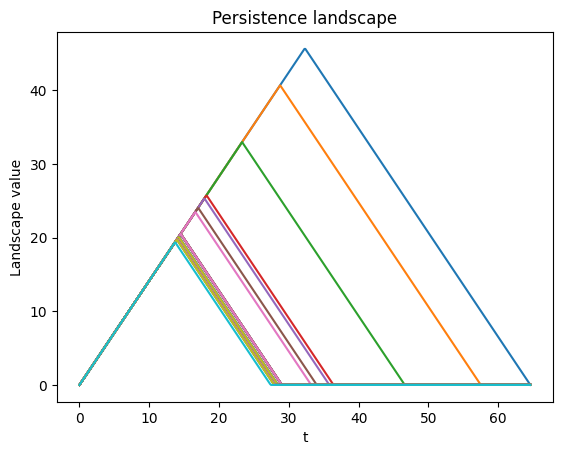

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from gudhi.representations import Landscape

# Keep only finite points
pd = pd_h5[np.isfinite(pd_h5).all(axis=1)]

L = Landscape(num_landscapes=30, resolution=500, keep_endpoints=True)
L.fit([pd])
vec = L.transform([pd])[0]

landscapes = vec.reshape(L.num_landscapes, L.resolution)

# Use the fitted grid, not L.sample_range
x = L.grid_

for k in range(L.num_landscapes):
    plt.plot(x, landscapes[k], label=fr'$\lambda_{k+1}$')

plt.xlabel("t")
plt.ylabel("Landscape value")
plt.title("Persistence landscape")
#plt.legend()
plt.show()